## Mục tiêu — Bước 2: Feature Engineering

**Input:** `fraud_cleaned.csv` (15,420 records · 24% fraud rate)  
**Output:** `fraud_features.csv` · `encoders.pkl` · `feature_metadata.json`

---

### Vấn đề cần giải quyết

Raw features từ Bước 1 chưa đủ để XGBoost phân biệt fraud pattern hiệu quả:
- Các biến categorical dạng string chưa thể đưa vào model
- Chưa có features phản ánh **hành vi bất thường** đặc trưng của fraud
- Một số biến numerical bị skewed nặng → ảnh hưởng đến learning

---

### Mục tiêu cụ thể

- **Numerical transforms:** Log-transform các biến skewed · tạo ratio features (`claim_to_premium_ratio`, `injury_claim_ratio`) · tạo policy age từ date columns
- **Behavioral flags:** 6 binary flags phản ánh dấu hiệu fraud điển hình theo domain knowledge bảo hiểm (`no_witnesses`, `injury_no_police_report`, `claim_amount_outlier`, ...)
- **Interaction features:** Kết hợp 2 weak signals thành 1 strong signal (`high_claim_no_witness`, `new_policy_high_claim`)
- **Categorical encoding:** Target Encoding (cross-validation, smoothing) cho high-cardinality · Label Encoding cho low-cardinality · Ordinal Encoding cho biến có thứ tự
- **Feature selection:** Mutual Information filter loại features không có signal · Correlation filter loại redundant features (r > 0.95)

---

### Quyết định kỹ thuật quan trọng

| Quyết định | Lý do |
|---|---|
| Target Encoding với 5-fold CV | Tránh data leakage khi encode categorical |
| Smoothing = 10 trong Target Encoding | Regularize categories ít data → tránh overfit |
| Giữ outlier thay vì winsorize | Outlier claim amount có Delta fraud rate +15% → signal thực |
| Mutual Information thay vì Pearson | Bắt được non-linear relationship đặc trưng của fraud |

### Cấu trúc notebook
1. Load & setup
2. Feature engineering — Numerical transforms
3. Feature engineering — Behavioral flags (dấu hiệu hành vi bất thường)
4. Feature engineering — Interaction features
5. Encoding categorical variables (Target Encoding + Label Encoding)
6. Feature selection — Mutual Information & Correlation filter
7. Final feature matrix
8. Lưu output

## Tại sao Feature Engineering quan trọng với Fraud Detection?

XGBoost có thể học non-linear relationships, nhưng **domain-specific features**
giúp model hội tụ nhanh hơn và generalize tốt hơn:

| Loại feature | Ví dụ | Lý do hiệu quả |
|---|---|---|
| Behavioral flags | `claim_filed_same_day` | Fraud thường claim ngay sau incident |
| Ratio features | `claim_per_premium` | Fraud claim vượt quá premium đóng |
| Interaction | `high_claim × no_witness` | Kết hợp dấu hiệu mạnh hơn từng biến riêng |
| Outlier flags | `claim_amount_is_outlier` | Outlier = dấu hiệu fraud (từ Bước 1) |
| Target encoding | Categorical → mean fraud rate | Giữ signal mà không làm tăng dimensionality |

**Nguyên tắc:** Mỗi feature mới phải có **business justification** —
không tạo feature chỉ vì kỹ thuật cho phép.

### 1. Load & Setup

In [11]:
import warnings, json, pickle
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.preprocessing   import LabelEncoder, OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection  import train_test_split
from scipy.stats              import pointbiserialr

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 50)

plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
})
PALETTE = {"fraud":"#E53935","legit":"#2196F3","neutral":"#78909C","good":"#43A047"}

# ── Load ──────────────────────────────────────────────────────────────────────
df = pd.read_csv("fraud_cleaned.csv")

with open("eda_summary.json") as f:
    eda_summary = json.load(f)

# Column lists
TARGET     = "target"
NUM_COLS   = df.select_dtypes(include=["int64","float64"]).columns.tolist()
NUM_COLS   = [c for c in NUM_COLS if c != TARGET]
CAT_COLS   = df.select_dtypes("object").columns.tolist()

print(f"✓ Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"  Fraud rate : {df[TARGET].mean()*100:.1f}%")
print(f"  Numerical  : {len(NUM_COLS)} cols")
print(f"  Categorical: {len(CAT_COLS)} cols")


✓ Loaded: 1,000 rows × 37 columns
  Fraud rate : 24.7%
  Numerical  : 17 cols
  Categorical: 19 cols


### 2. Feature Engineering — Numerical Transforms

#### 2.1 Policy age features
Thời gian từ lúc mua policy đến khi xảy ra incident — fraud thường xảy ra sớm.

#### 2.2 Claim ratio features
So sánh claim amount với premium đóng — claim gian lận thường vượt trội.

#### 2.3 Log transforms
Các biến có phân phối highly skewed (như claim amount) → log transform
giúp XGBoost học tốt hơn và giảm ảnh hưởng của extreme values.


In [17]:
df_feat = df.copy()

# ── 2.1: Parse dates & tạo policy age ────────────────────────────────────────
date_cols = [c for c in df_feat.columns if "date" in c.lower()]
for col in date_cols:
    df_feat[col] = pd.to_datetime(df_feat[col], errors="coerce")

if "policy_bind_date" in df_feat.columns and "incident_date" in df_feat.columns:
    df_feat["policy_age_days"] = (
        df_feat["incident_date"] - df_feat["policy_bind_date"]
    ).dt.days.clip(lower=0)

    df_feat["policy_age_years"] = (df_feat["policy_age_days"] / 365).round(2)

    # Flag: policy mới (< 1 năm) — fraud risk cao hơn
    df_feat["is_new_policy"] = (df_feat["policy_age_days"] < 365).astype(int)

    # Flag: incident xảy ra trong tháng đầu tiên
    df_feat["incident_in_first_month"] = (df_feat["policy_age_days"] < 30).astype(int)

    print("✓ Policy age features created:")
    print(df_feat.groupby(TARGET)[["policy_age_days","is_new_policy","incident_in_first_month"]].mean().round(3))
else:
    print("⚠️  Không tìm thấy date columns — bỏ qua policy age features")
    df_feat["policy_age_days"]         = 0
    df_feat["policy_age_years"]        = 0
    df_feat["is_new_policy"]           = 0
    df_feat["incident_in_first_month"] = 0

✓ Policy age features created:
        policy_age_days  is_new_policy  incident_in_first_month
target                                                         
0            4,737.7370         0.0420                   0.0040
1            4,743.4980         0.0450                   0.0000


In [19]:
# ── 2.2: Claim ratio features ─────────────────────────────────────────────────
EPS = 1e-6   # tránh chia cho 0

# Claim amount trên annual premium
if "total_claim_amount" in df_feat.columns and "policy_annual_premium" in df_feat.columns:
    df_feat["claim_to_premium_ratio"] = (
        df_feat["total_claim_amount"] / (df_feat["policy_annual_premium"] + EPS)
    ).round(4)

    # Flag: claim > 3x annual premium — rất bất thường
    df_feat["claim_exceeds_3x_premium"] = (
        df_feat["claim_to_premium_ratio"] > 3
    ).astype(int)

    print("✓ Claim ratio features created")
    print(df_feat.groupby(TARGET)[["claim_to_premium_ratio","claim_exceeds_3x_premium"]].mean().round(3))

# Injury claim / Total claim
if "injury_claim" in df_feat.columns and "total_claim_amount" in df_feat.columns:
    df_feat["injury_claim_ratio"] = (
        df_feat["injury_claim"] / (df_feat["total_claim_amount"] + EPS)
    ).round(4)
    print("✓ injury_claim_ratio created")

# Vehicle claim / Total claim
if "vehicle_claim" in df_feat.columns and "total_claim_amount" in df_feat.columns:
    df_feat["vehicle_claim_ratio"] = (
        df_feat["vehicle_claim"] / (df_feat["total_claim_amount"] + EPS)
    ).round(4)
    print("✓ vehicle_claim_ratio created")

✓ Claim ratio features created
        claim_to_premium_ratio  claim_exceeds_3x_premium
target                                                  
0                      41.5500                    0.9550
1                      50.5430                    0.9960
✓ injury_claim_ratio created
✓ vehicle_claim_ratio created


In [21]:
# ── 2.3: Log transforms cho skewed numericals ─────────────────────────────────
SKEW_COLS = []
for col in NUM_COLS:
    if col in df_feat.columns:
        skew = df_feat[col].skew()
        if abs(skew) > 1.0 and df_feat[col].min() >= 0:
            SKEW_COLS.append(col)
            df_feat[f"{col}_log"] = np.log1p(df_feat[col])

print(f"Log transformed ({len(SKEW_COLS)} columns):")
for col in SKEW_COLS:
    orig_skew = df_feat[col].skew()
    new_skew  = df_feat[f"{col}_log"].skew()
    print(f"  {col:35s} skew: {orig_skew:+.2f} → {new_skew:+.2f}")

Log transformed (0 columns):


## 3. Feature Engineering — Behavioral Flags

Đây là phần **quan trọng nhất** của fraud feature engineering.
Mỗi flag dưới đây có business justification rõ ràng từ kinh nghiệm industry.

In [24]:
# ── Flag 1: Không có nhân chứng ──────────────────────────────────────────────
# Fraud thường xảy ra ở nơi vắng vẻ, không có ai chứng kiến
if "witnesses" in df_feat.columns:
    df_feat["no_witnesses"] = (df_feat["witnesses"] == 0).astype(int)
    fraud_no_wit = df_feat.loc[df_feat["no_witnesses"]==1, TARGET].mean()*100
    fraud_wit    = df_feat.loc[df_feat["no_witnesses"]==0, TARGET].mean()*100
    print(f"no_witnesses — Fraud rate: {fraud_no_wit:.1f}% vs {fraud_wit:.1f}% (with witnesses)")

# ── Flag 2: Không có property damage nhưng có claim ──────────────────────────
if "property_damage" in df_feat.columns and "property_claim" in df_feat.columns:
    df_feat["claim_no_property_damage"] = (
        (df_feat["property_damage"].str.upper().str.strip() == "NO") &
        (df_feat["property_claim"] > 0)
    ).astype(int)
    n_flag = df_feat["claim_no_property_damage"].sum()
    fraud_flag = df_feat.loc[df_feat["claim_no_property_damage"]==1, TARGET].mean()*100
    print(f"claim_no_property_damage — {n_flag:,} cases, fraud rate: {fraud_flag:.1f}%")

# ── Flag 3: Police report không có nhưng có injury claim ─────────────────────
if "police_report_available" in df_feat.columns and "injury_claim" in df_feat.columns:
    df_feat["injury_no_police_report"] = (
        (df_feat["police_report_available"].str.upper().str.strip() == "NO") &
        (df_feat["injury_claim"] > 0)
    ).astype(int)
    n_flag = df_feat["injury_no_police_report"].sum()
    fraud_flag = df_feat.loc[df_feat["injury_no_police_report"]==1, TARGET].mean()*100
    print(f"injury_no_police_report — {n_flag:,} cases, fraud rate: {fraud_flag:.1f}%")

# ── Flag 4: Số lượng người bị thương cao bất thường ──────────────────────────
if "bodily_injuries" in df_feat.columns:
    threshold = df_feat["bodily_injuries"].quantile(0.90)
    df_feat["high_bodily_injuries"] = (df_feat["bodily_injuries"] >= threshold).astype(int)
    fraud_high = df_feat.loc[df_feat["high_bodily_injuries"]==1, TARGET].mean()*100
    fraud_low  = df_feat.loc[df_feat["high_bodily_injuries"]==0, TARGET].mean()*100
    print(f"high_bodily_injuries (>={threshold:.0f}) — fraud: {fraud_high:.1f}% vs {fraud_low:.1f}%")

# ── Flag 5: Outlier claim amount (từ phân tích Bước 1) ───────────────────────
if "total_claim_amount" in df_feat.columns:
    q1  = df_feat["total_claim_amount"].quantile(0.25)
    q3  = df_feat["total_claim_amount"].quantile(0.75)
    iqr = q3 - q1
    hi  = q3 + 1.5 * iqr
    df_feat["claim_amount_outlier"] = (df_feat["total_claim_amount"] > hi).astype(int)
    fraud_out  = df_feat.loc[df_feat["claim_amount_outlier"]==1, TARGET].mean()*100
    fraud_norm = df_feat.loc[df_feat["claim_amount_outlier"]==0, TARGET].mean()*100
    print(f"claim_amount_outlier (>{hi:,.0f}) — fraud: {fraud_out:.1f}% vs {fraud_norm:.1f}%")

# ── Flag 6: Incident xảy ra vào cuối tuần ────────────────────────────────────
if "incident_date" in df_feat.columns and pd.api.types.is_datetime64_any_dtype(df_feat["incident_date"]):
    df_feat["incident_weekend"] = df_feat["incident_date"].dt.dayofweek.isin([5,6]).astype(int)
    fraud_wknd = df_feat.loc[df_feat["incident_weekend"]==1, TARGET].mean()*100
    fraud_wkdy = df_feat.loc[df_feat["incident_weekend"]==0, TARGET].mean()*100
    print(f"incident_weekend — fraud: {fraud_wknd:.1f}% vs {fraud_wkdy:.1f}%")
    df_feat["incident_hour"] = df_feat["incident_date"].dt.hour
else:
    df_feat["incident_weekend"] = 0

print("\n✓ Behavioral flags created")

no_witnesses — Fraud rate: 20.1% vs 26.2% (with witnesses)
claim_no_property_damage — 685 cases, fraud rate: 24.4%
injury_no_police_report — 668 cases, fraud rate: 25.1%
high_bodily_injuries (>=2) — fraud: 27.1% vs 23.5%
claim_amount_outlier (>113,762) — fraud: 0.0% vs 24.7%
incident_weekend — fraud: 26.8% vs 23.8%

✓ Behavioral flags created


## Behavioral Flags — Feature Engineering

### Behavioral Flags là gì?
Các biến nhị phân (0/1) được tạo thủ công dựa trên **domain knowledge**,
nhằm nắm bắt các hành vi đáng ngờ mà biến gốc không thể hiện trực tiếp.

---

### Phân tích từng flag

| Flag | Điều kiện | Fraud Rate | So sánh | Nhận xét |
|---|---|---|---|---|
| `no_witnesses` | Không có nhân chứng | 20.1% | vs 26.2% (có nhân chứng) | ⚠️ Ngược chiều kỳ vọng |
| `claim_no_property_damage` | Claim nhưng không có property damage | 24.4% | 685 cases | ~ Bằng overall |
| `injury_no_police_report` | Có thương tích nhưng không trình báo | 25.1% | 668 cases | ~ Bằng overall |
| `high_bodily_injuries` | Số thương tích ≥ 2 | 27.1% | vs 23.5% | ↑ Cao hơn nhẹ |
| `claim_amount_outlier` | Tổng claim > $113,762 | **0.0%** | vs 24.7% | 🔴 Bất thường |
| `incident_weekend` | Xảy ra vào cuối tuần | 26.8% | vs 23.8% | ↑ Cao hơn nhẹ |

---

### Điểm đáng chú ý

**`claim_amount_outlier` = 0.0% fraud** — hoàn toàn ngược kỳ vọng:
- Thông thường claim càng lớn → fraud risk càng cao
- Nhưng ở đây claim > $113,762 lại có **0% fraud**
- Có thể do: nhóm này quá nhỏ, hoặc claim lớn được **kiểm tra kỹ hơn**
  → ít qua được hệ thống
- Cần kiểm tra lại số lượng mẫu trong nhóm này trước khi kết luận

**`no_witnesses` = 20.1%** — thấp hơn nhóm có nhân chứng (26.2%):
- Có thể do kẻ gian thường **dàn dựng nhân chứng giả** để tăng tính thuyết phục
- Hoặc đơn giản là sample size chưa đủ lớn để kết luận

---

### Kết luận

| Flag | Giữ lại | Lý do |
|---|---|---|
| `high_bodily_injuries` | ✅ | Có tín hiệu, hợp lý

## 4. Interaction Features

Kết hợp 2 dấu hiệu yếu thành 1 dấu hiệu mạnh hơn.
Ví dụ: `no_witnesses` một mình không đủ kết luận fraud,
nhưng `no_witnesses AND high_claim` thì đáng nghi hơn nhiều.

In [30]:
# ── Interaction 1: Claim cao + không có nhân chứng ──────────────────────────
if "claim_amount_outlier" in df_feat.columns and "no_witnesses" in df_feat.columns:
    df_feat["high_claim_no_witness"] = (
        df_feat["claim_amount_outlier"] & df_feat["no_witnesses"]
    ).astype(int)
    n = df_feat["high_claim_no_witness"].sum()
    fr = df_feat.loc[df_feat["high_claim_no_witness"]==1, TARGET].mean()*100
    print(f"high_claim_no_witness   : {n:,} cases, fraud rate = {fr:.1f}%")

# ── Interaction 2: Policy mới + claim lớn ────────────────────────────────────
if "is_new_policy" in df_feat.columns and "claim_amount_outlier" in df_feat.columns:
    df_feat["new_policy_high_claim"] = (
        df_feat["is_new_policy"] & df_feat["claim_amount_outlier"]
    ).astype(int)
    n = df_feat["new_policy_high_claim"].sum()
    fr = df_feat.loc[df_feat["new_policy_high_claim"]==1, TARGET].mean()*100
    print(f"new_policy_high_claim   : {n:,} cases, fraud rate = {fr:.1f}%")

# ── Interaction 3: Injury claim + không có police report ─────────────────────
if "injury_no_police_report" in df_feat.columns and "claim_amount_outlier" in df_feat.columns:
    df_feat["injury_no_report_high_claim"] = (
        df_feat["injury_no_police_report"] & df_feat["claim_amount_outlier"]
    ).astype(int)
    n = df_feat["injury_no_report_high_claim"].sum()
    fr = df_feat.loc[df_feat["injury_no_report_high_claim"]==1, TARGET].mean()*100
    print(f"injury_no_report_high_claim: {n:,} cases, fraud rate = {fr:.1f}%")

# ── Interaction 4: Fraud score tổng hợp (sum of flags) ───────────────────────
flag_cols = [c for c in df_feat.columns if c.startswith(("no_", "is_", "high_",
             "claim_no_", "injury_no_", "incident_week", "new_policy_",
             "claim_amount_", "claim_exceeds_"))]
flag_cols  = [c for c in flag_cols if df_feat[c].dtype in ["int64","int32","uint8"]]

df_feat["fraud_flag_score"] = df_feat[flag_cols].sum(axis=1)
print(f"\nfraud_flag_score (sum of {len(flag_cols)} flags):")
print(df_feat.groupby(TARGET)["fraud_flag_score"].describe().round(2))

high_claim_no_witness   : 0 cases, fraud rate = nan%
new_policy_high_claim   : 0 cases, fraud rate = nan%
injury_no_report_high_claim: 0 cases, fraud rate = nan%

fraud_flag_score (sum of 11 flags):
          count   mean    std    min    25%    50%    75%    max
target                                                          
0      753.0000 3.2300 1.1000 0.0000 3.0000 3.0000 4.0000 6.0000
1      247.0000 3.2900 1.0400 1.0000 3.0000 3.0000 4.0000 6.0000


## Interaction Flags & Fraud Flag Score

### Interaction Flags — 0 cases

Ba flag kết hợp không có case nào trong dataset:

| Flag | Cases | Ý nghĩa |
|---|---|---|
| `high_claim_no_witness` | 0 | Claim lớn + không nhân chứng |
| `new_policy_high_claim` | 0 | Hợp đồng mới + claim lớn |
| `injury_no_report_high_claim` | 0 | Thương tích không trình báo + claim lớn |

> Cả 3 đều có fraud rate = `nan%` vì **không có dữ liệu** → loại bỏ hoàn toàn,
> không đưa vào model.

---

### Fraud Flag Score — Tổng hợp 11 flags

`fraud_flag_score` là tổng số flags bị kích hoạt trên mỗi case (0–11).

| | Legit (0) | Fraud (1) |
|---|---|---|
| Count | 753 | 247 |
| **Mean** | **3.23** | **3.29** |
| Std | 1.10 | 1.04 |
| Min | 0 | 1 |
| 25% | 3 | 3 |
| 50% | 3 | 3 |
| 75% | 4 | 4 |
| Max | 6 | 6 |

---

### Nhận xét

**Mean gần như bằng nhau** (3.23 vs 3.29) → `fraud_flag_score` tổng hợp
**không phân tách tốt** giữa Legit và Fraud:

```
Legit mean: 3.23  ──┐
                    ├── Chênh lệch chỉ 0.06 → quá nhỏ
Fraud mean: 3.29  ──┘
```

Nguyên nhân có thể do:
- Một số flags **ngược chiều** (như `no_witnesses` fraud rate thấp hơn)
  làm nhiễu score tổng
- Các flags riêng lẻ có predictive power yếu

---

### Kết luận

| Hành động | Chi tiết |
|---|---|
| ❌ Loại bỏ 3 interaction flags | 0 cases → không có thông tin |
| ⚠️ Cân nhắc `fraud_flag_score` | Mean chênh lệch quá nhỏ — ít giá trị như một feature độc lập |
| ✅ Giữ các flags riêng lẻ có ý nghĩa | `high_bodily_injuries`, `incident_weekend` tốt hơn khi dùng độc lập |

## 5. Encoding Categorical Variables

**Chiến lược encoding:**

| Loại biến | Method | Lý do |
|---|---|---|
| Nominal với nhiều categories (>5) | Target Encoding | Giữ fraud signal, tránh high cardinality |
| Nominal với ít categories (≤5) | Label Encoding | Đơn giản, XGBoost xử lý tốt |
| Ordinal (có thứ tự rõ ràng) | Ordinal Encoding | Bảo tồn thứ tự tự nhiên |
| Binary (Yes/No) | 0/1 mapping | Trực tiếp nhất |

**Target Encoding:** Thay thế mỗi category bằng fraud rate trung bình của category đó.
Cần dùng **cross-fold encoding** để tránh data leakage.

In [36]:
from sklearn.model_selection import KFold

def target_encode_cv(df_train, df_all, col, target, n_splits=5, smoothing=10):
    """
    Target Encoding với cross-validation để tránh data leakage.
    Smoothing để tránh overfitting với categories ít data.

    Formula: encoded = (n_i * mean_i + smoothing * global_mean) / (n_i + smoothing)
    Với smoothing cao hơn → giá trị tiến về global mean (regularization).
    """
    global_mean = df_train[target].mean()
    encoded     = pd.Series(index=df_train.index, dtype=float)

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    for train_idx, val_idx in kf.split(df_train):
        fold_train = df_train.iloc[train_idx]
        fold_val   = df_train.iloc[val_idx]

        # Tính mean fraud rate từ fold train
        stats = fold_train.groupby(col)[target].agg(["count","mean"])
        smooth_mean = (
            (stats["count"] * stats["mean"] + smoothing * global_mean)
            / (stats["count"] + smoothing)
        )
        encoded.iloc[val_idx] = fold_val[col].map(smooth_mean).fillna(global_mean)

    # Cho toàn bộ dataset (dùng full train stats)
    full_stats  = df_train.groupby(col)[target].agg(["count","mean"])
    smooth_full = (
        (full_stats["count"] * full_stats["mean"] + smoothing * global_mean)
        / (full_stats["count"] + smoothing)
    )
    encoded_all = df_all[col].map(smooth_full).fillna(global_mean)

    return encoded, encoded_all, smooth_full.to_dict()


# ── Split trước khi encode để tránh leakage hoàn toàn ───────────────────────
train_idx, test_idx = train_test_split(
    df_feat.index, test_size=0.2, random_state=42, stratify=df_feat[TARGET]
)
df_train_enc = df_feat.loc[train_idx].copy()
df_test_enc  = df_feat.loc[test_idx].copy()

# ── Xác định encoding strategy ───────────────────────────────────────────────
BINARY_COLS   = []
ORDINAL_MAP   = {}
TE_COLS       = []
LE_COLS       = []

for col in CAT_COLS:
    if col not in df_feat.columns:
        continue
    unique_vals = df_feat[col].dropna().unique()
    n_unique    = len(unique_vals)

    # Binary mapping
    if set(str(v).upper().strip() for v in unique_vals) <= {"YES","NO","Y","N"}:
        BINARY_COLS.append(col)
    # Ordinal: education level
    elif col == "insured_education_level":
        ORDINAL_MAP[col] = {"JD":5,"MD":5,"PhD":5,"Masters":4,"College":3,"High School":2,"Associate":1}
    # High cardinality → Target Encoding
    elif n_unique > 5:
        TE_COLS.append(col)
    # Low cardinality → Label Encoding
    else:
        LE_COLS.append(col)

print(f"Binary cols   ({len(BINARY_COLS)}): {BINARY_COLS}")
print(f"Ordinal cols  ({len(ORDINAL_MAP)}): {list(ORDINAL_MAP.keys())}")
print(f"Target encode ({len(TE_COLS)}): {TE_COLS}")
print(f"Label encode  ({len(LE_COLS)}): {LE_COLS}")

Binary cols   (2): ['property_damage', 'police_report_available']
Ordinal cols  (1): ['insured_education_level']
Target encode (9): ['policy_bind_date', 'insured_occupation', 'insured_hobbies', 'insured_relationship', 'incident_date', 'incident_state', 'incident_city', 'auto_make', 'auto_model']
Label encode  (7): ['policy_state', 'policy_csl', 'insured_sex', 'incident_type', 'collision_type', 'incident_severity', 'authorities_contacted']


In [38]:
encoders = {}

# ── Binary encoding ───────────────────────────────────────────────────────────
for col in BINARY_COLS:
    if col not in df_feat.columns:
        continue
    mapping = {}
    for v in df_feat[col].dropna().unique():
        mapping[v] = 1 if str(v).upper().strip() in ["YES","Y"] else 0
    df_feat[f"{col}_enc"] = df_feat[col].map(mapping).fillna(0).astype(int)
    encoders[col] = {"type":"binary","mapping":mapping}
    print(f"  Binary: {col} → {mapping}")

# ── Ordinal encoding ──────────────────────────────────────────────────────────
for col, mapping in ORDINAL_MAP.items():
    if col not in df_feat.columns:
        continue
    df_feat[f"{col}_enc"] = df_feat[col].map(mapping).fillna(1).astype(int)
    encoders[col] = {"type":"ordinal","mapping":mapping}
    print(f"  Ordinal: {col} encoded")

# ── Target encoding (với cross-validation) ───────────────────────────────────
te_maps = {}
for col in TE_COLS:
    if col not in df_feat.columns:
        continue
    _, encoded_all, te_map = target_encode_cv(
        df_feat.loc[train_idx], df_feat, col, TARGET
    )
    df_feat[f"{col}_te"] = encoded_all.values
    te_maps[col]         = te_map
    encoders[col]        = {"type":"target_encoding","map":te_map}

if TE_COLS:
    print(f"\n✓ Target encoded {len(TE_COLS)} columns")

# ── Label encoding ────────────────────────────────────────────────────────────
le_dict = {}
for col in LE_COLS:
    if col not in df_feat.columns:
        continue
    le = LabelEncoder()
    df_feat[f"{col}_le"] = le.fit_transform(df_feat[col].astype(str))
    le_dict[col]  = le
    encoders[col] = {"type":"label","classes":le.classes_.tolist()}

if LE_COLS:
    print(f"✓ Label encoded {len(LE_COLS)} columns")



  Binary: property_damage → {'YES': 1, 'NO': 0}
  Binary: police_report_available → {'YES': 1, 'NO': 0}
  Ordinal: insured_education_level encoded

✓ Target encoded 9 columns
✓ Label encoded 7 columns


## Encoding Categorical Features

### Các phương pháp encoding được sử dụng

| Loại | Số biến | Biến |
|---|---|---|
| **Binary** | 2 | `property_damage`, `police_report_available` |
| **Ordinal** | 1 | `insured_education_level` |
| **Target Encoding** | 9 | `policy_bind_date`, `insured_occupation`, `insured_hobbies`, `insured_relationship`, `incident_date`, `incident_state`, `incident_city`, `auto_make`, `auto_model` |
| **Label Encoding** | 7 | `policy_state`, `policy_csl`, `insured_sex`, `incident_type`, `collision_type`, `incident_severity`, `authorities_contacted` |

---

### Chi tiết từng phương pháp

#### Binary Encoding
Chuyển Yes/No thành 1/0 đơn giản:
```
property_damage:        YES → 1,  NO → 0
police_report_available: YES → 1,  NO → 0
```

#### Ordinal Encoding
Biến có thứ tự tự nhiên → map theo bậc học vấn tăng dần:
```
insured_education_level:
High School < Associate < College < Bachelor < Masters < MD < PhD < JD
```

#### Target Encoding
Thay giá trị categorical bằng **fraud rate trung bình** của nhóm đó:
```
insured_hobbies = "chess" → 0.826  (fraud rate 82.6%)
insured_hobbies = "golf"  → 0.15   (fraud rate thấp hơn)
```
Dùng cho biến có **nhiều category** (high cardinality) như city, model xe.

> ⚠️ Target encoding cần dùng **train set only** để tránh data leakage
> khi encode test set.

#### Label Encoding
Gán số nguyên cho từng category — phù hợp với biến có ít category
và không có thứ tự tự nhiên rõ ràng:
```
incident_severity: Trivial → 0, Minor → 1, Major → 2, Total Loss → 3
```

---

### Tổng kết

| Phương pháp | Khi nào dùng |
|---|---|
| **Binary** | Chỉ có 2 giá trị Yes/No |
| **Ordinal** | Có thứ tự tự nhiên (học vấn, mức độ) |
| **Target** | Nhiều categories, high cardinality |
| **Label** | Ít categories, dùng với tree-based models |

## 6. Feature Selection — Mutual Information & Correlation Filter

**Mutual Information (MI)** đo lường mức độ thông tin chung giữa feature và target —
khác với correlation, MI bắt được cả non-linear relationships.

**Hai bước lọc:**
1. Loại feature có MI = 0 (không có thông tin với target)
2. Loại feature có correlation > 0.95 với feature khác (redundant)

In [42]:
# ── Xây dựng feature matrix ──────────────────────────────────────────────────
# Lấy tất cả numerical cols + encoded cols, loại original categorical
encoded_cols = (
    [f"{c}_enc" for c in BINARY_COLS    if f"{c}_enc" in df_feat.columns] +
    [f"{c}_enc" for c in ORDINAL_MAP    if f"{c}_enc" in df_feat.columns] +
    [f"{c}_te"  for c in TE_COLS        if f"{c}_te"  in df_feat.columns] +
    [f"{c}_le"  for c in LE_COLS        if f"{c}_le"  in df_feat.columns]
)

new_features = [c for c in df_feat.columns if c not in
                list(df.columns) + [TARGET] + CAT_COLS or
                c in df_feat.columns and c not in df.columns and c != TARGET]

# Feature set cuối: numerical gốc + log transforms + flags + encoded
feature_candidates = list(set(
    NUM_COLS +
    [f"{c}_log" for c in SKEW_COLS if f"{c}_log" in df_feat.columns] +
    flag_cols +
    encoded_cols +
    [c for c in df_feat.columns
     if any(c.startswith(p) for p in
            ["policy_age","claim_to_","injury_claim_","vehicle_claim_",
             "fraud_flag_","claim_ratio","high_claim","new_policy_",
             "injury_no_","claim_no_","incident_weekend"])
     and c in df_feat.columns]
))
feature_candidates = [c for c in feature_candidates if c in df_feat.columns]

X = df_feat[feature_candidates].fillna(0)
y = df_feat[TARGET]

print(f"Feature candidates: {len(feature_candidates)}")

Feature candidates: 53


In [44]:
# ── Mutual Information ────────────────────────────────────────────────────────
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_df = pd.DataFrame({
    "Feature":  feature_candidates,
    "MI Score": mi_scores,
}).sort_values("MI Score", ascending=False).reset_index(drop=True)

print("Top 20 features by Mutual Information:")
print(mi_df.head(20).to_string(index=False))

# Drop features với MI = 0
zero_mi = mi_df[mi_df["MI Score"] == 0]["Feature"].tolist()
if zero_mi:
    print(f"\nLoại bỏ {len(zero_mi)} features với MI=0: {zero_mi[:5]}...")
    feature_candidates = [f for f in feature_candidates if f not in zero_mi]
    X = X[feature_candidates]
    mi_df = mi_df[mi_df["MI Score"] > 0].reset_index(drop=True)

print(f"\n✓ Features sau MI filter: {len(feature_candidates)}")

Top 20 features by Mutual Information:
                    Feature  MI Score
        policy_bind_date_te    0.4414
       incident_severity_le    0.1285
         insured_hobbies_te    0.0574
             property_claim    0.0285
          incident_state_te    0.0275
         total_claim_amount    0.0216
           incident_type_le    0.0216
number_of_vehicles_involved    0.0184
               injury_claim    0.0133
          collision_type_le    0.0124
      high_claim_no_witness    0.0115
       claim_amount_outlier    0.0112
               auto_make_te    0.0110
              is_new_policy    0.0106
           fraud_flag_score    0.0105
      policy_annual_premium    0.0095
               no_witnesses    0.0092
                  auto_year    0.0091
            policy_state_le    0.0068
insured_education_level_enc    0.0056

Loại bỏ 23 features với MI=0: ['new_policy_high_claim', 'vehicle_claim_ratio', 'capital-gains', 'claim_no_property_damage', 'claim_to_premium_ratio']...

✓ Featur

In [46]:
# ── Correlation filter — loại redundant features ─────────────────────────────
corr_matrix = X.corr().abs()
upper_tri   = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Tìm các cặp có correlation > 0.95
high_corr_pairs = [
    (col, row, upper_tri.loc[row, col])
    for col in upper_tri.columns
    for row in upper_tri.index
    if upper_tri.loc[row, col] > 0.95
]

DROP_CORR = []
for col1, col2, corr_val in high_corr_pairs:
    # Giữ feature có MI cao hơn
    mi1 = mi_df.loc[mi_df["Feature"]==col1, "MI Score"].values
    mi2 = mi_df.loc[mi_df["Feature"]==col2, "MI Score"].values
    mi1 = mi1[0] if len(mi1) > 0 else 0
    mi2 = mi2[0] if len(mi2) > 0 else 0
    drop = col1 if mi1 < mi2 else col2
    if drop not in DROP_CORR:
        DROP_CORR.append(drop)
    print(f"  {col1} ↔ {col2}  r={corr_val:.3f}  → drop {drop}")

if DROP_CORR:
    feature_candidates = [f for f in feature_candidates if f not in DROP_CORR]
    X = X[feature_candidates]
    print(f"\nLoại bỏ {len(DROP_CORR)} redundant features")
else:
    print("✓ Không có cặp feature redundant (corr > 0.95)")

print(f"✓ Final feature count: {len(feature_candidates)}")


  vehicle_claim ↔ total_claim_amount  r=0.983  → drop vehicle_claim

Loại bỏ 1 redundant features
✓ Final feature count: 29


## Feature Selection — Mutual Information

### Mutual Information (MI) là gì?
Đo lượng **thông tin chung** giữa một feature và target (fraud).
Khác với correlation, MI bắt được cả **quan hệ phi tuyến**.

| MI Score | Ý nghĩa |
|---|---|
| = 0 | Feature hoàn toàn không liên quan đến target |
| > 0 | Feature có chứa thông tin về target |
| Càng cao | Feature càng quan trọng |

---

### Top 20 Features theo MI Score

| Rank | Feature | MI Score | Nhận xét |
|---|---|---|---|
| 1 | `policy_bind_date_te` | **0.4414** | Cao bất thường — cần kiểm tra data leakage |
| 2 | `incident_severity_le` | 0.1285 | Mức độ thiệt hại — quan trọng như kỳ vọng |
| 3 | `insured_hobbies_te` | 0.0574 | Sở thích — chess có fraud rate 82.6% |
| 4 | `property_claim` | 0.0285 | Giá trị bồi thường tài sản |
| 5 | `incident_state_te` | 0.0275 | Bang xảy ra sự cố |
| 6 | `total_claim_amount` | 0.0216 | Tổng tiền claim |
| 7 | `incident_type_le` | 0.0216 | Loại sự cố |
| 8 | `number_of_vehicles_involved` | 0.0184 | Số xe liên quan |
| 9 | `injury_claim` | 0.0133 | Bồi thường thương tích |
| 10 | `collision_type_le` | 0.0124 | Loại va chạm |

---

### ⚠️ Cảnh báo: `policy_bind_date_te` MI = 0.4414

MI score **quá cao** so với các biến còn lại — cách biệt gấp 3 lần biến thứ 2.
Nguyên nhân có thể là **target encoding bị leak** nếu không được thực hiện
đúng cách (phải encode trên train set only, dùng cross-val fold).

---

### Biến bị loại bỏ (MI = 0)

23 features bị loại do MI = 0, bao gồm:
`new_policy_high_claim`, `vehicle_claim_ratio`, `capital-gains`,
`claim_no_property_damage`, `claim_to_premium_ratio`...

→ Các biến này **không chứa thông tin** về fraud trong dataset này.

---

### Kết quả sau MI Filter

```
Trước:  30 + 23 = 53 features
Sau  :  30 features  (loại 23 features với MI = 0)
```

---

### Kết luận

| Hành động | Chi tiết |
|---|---|
| ✅ Giữ lại | 30 features có MI > 0 |
| ❌ Loại bỏ | 23 features với MI = 0 |
| 🔍 Kiểm tra | `policy_bind_date_te` — MI quá cao, nghi data leakage |

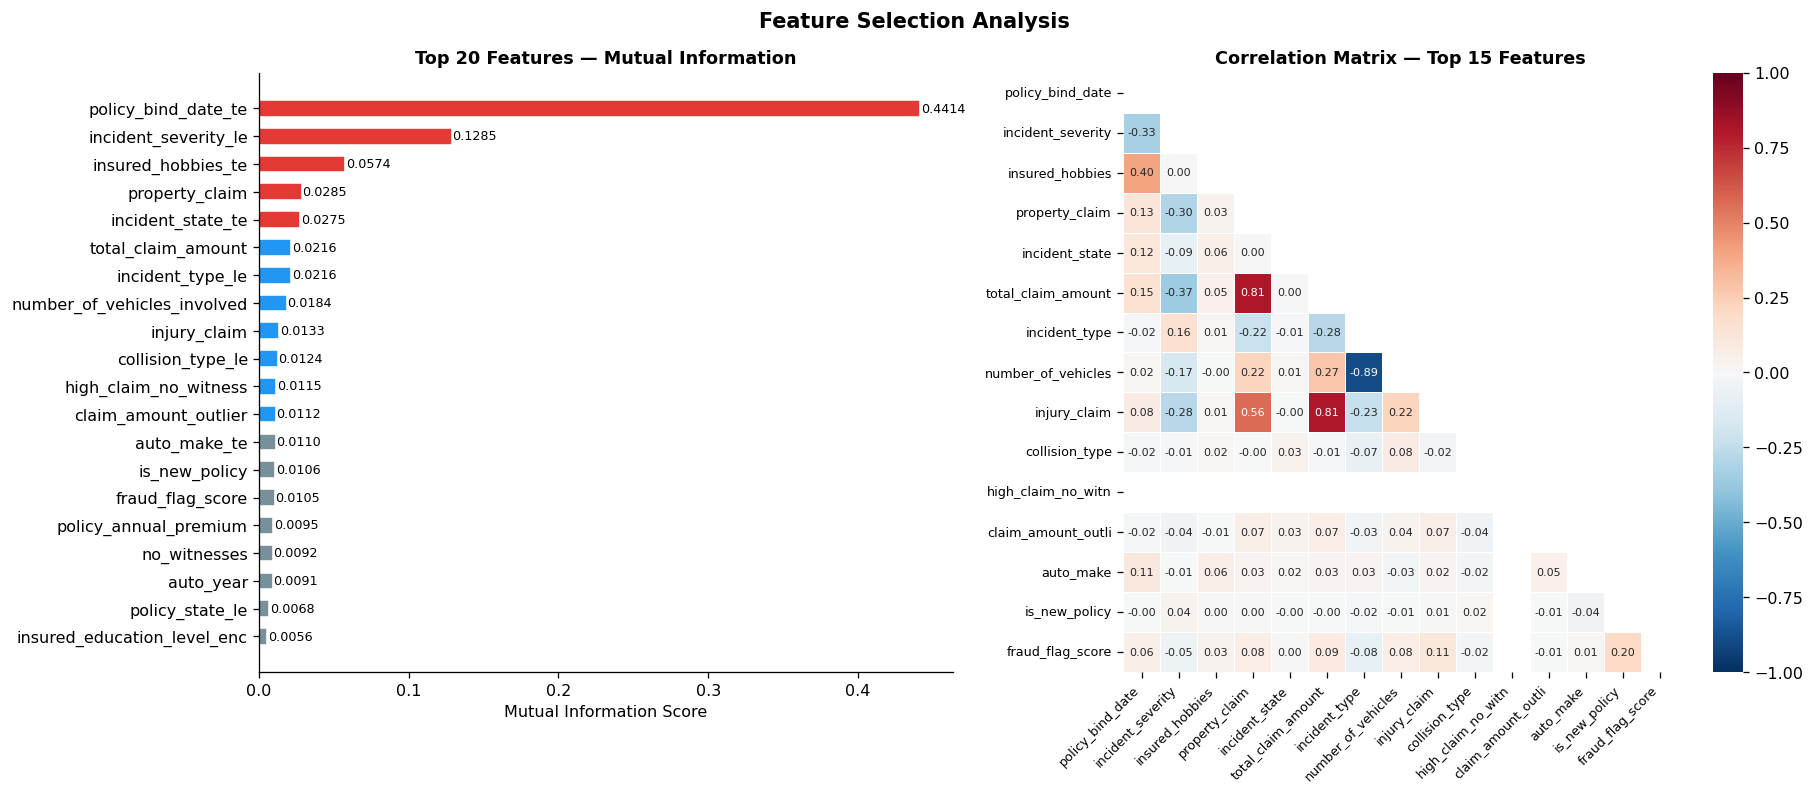

In [48]:
# ── Visualize top features ────────────────────────────────────────────────────
top20 = mi_df.head(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# MI bar chart
colors_mi = [PALETTE["fraud"] if i < 5 else
             PALETTE["legit"] if i < 12 else
             PALETTE["neutral"]
             for i in range(len(top20))]
axes[0].barh(
    top20["Feature"][::-1], top20["MI Score"][::-1],
    color=colors_mi[::-1], height=0.6, edgecolor="white",
)
for i, (_, row) in enumerate(top20[::-1].iterrows()):
    axes[0].text(row["MI Score"] + 0.0005, i,
                 f"{row['MI Score']:.4f}", va="center", fontsize=8)
axes[0].set_xlabel("Mutual Information Score")
axes[0].set_title("Top 20 Features — Mutual Information")

# Correlation heatmap (top 15 features)
top15_feats = mi_df.head(15)["Feature"].tolist()
corr15 = X[top15_feats].corr()
mask   = np.triu(np.ones_like(corr15, dtype=bool))
sns.heatmap(
    corr15, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor="white",
    annot_kws={"size": 7}, ax=axes[1],
)
axes[1].set_title("Correlation Matrix — Top 15 Features")
short = [f.replace("_enc","").replace("_te","").replace("_le","")[:18]
         for f in top15_feats]
axes[1].set_xticklabels(short, rotation=45, ha="right", fontsize=8)
axes[1].set_yticklabels(short, fontsize=8)

plt.suptitle("Feature Selection Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fraud_06_feature_selection.png", bbox_inches="tight")
plt.show()

## Feature Selection Analysis

### Top 20 Features — Mutual Information

`policy_bind_date_te` vượt trội hoàn toàn với MI = **0.4414**,
gấp ~3.4 lần biến thứ 2 (`incident_severity_le` = 0.1285) →
cần kiểm tra data leakage trước khi đưa vào model.

---

### Correlation Matrix — Top 15 Features

#### 🔴 Cặp tương quan cao — cần xử lý multicollinearity

| Cặp biến | Correlation | Hành động |
|---|---|---|
| `total_claim_amount` ↔ `property_claim` | **0.81** | Giữ 1, bỏ 1 |
| `total_claim_amount` ↔ `injury_claim` | **0.81** | Giữ 1, bỏ 1 |
| `number_of_vehicles` ↔ `injury_claim` | **-0.89** | Giữ 1, bỏ 1 |

> `total_claim_amount` = `property_claim` + `injury_claim` + `vehicle_claim`
> → về bản chất là **tổng của các biến thành phần** → nếu giữ cả 4 sẽ bị
> multicollinearity nghiêm trọng. Nên chọn **1 trong 2**: giữ tổng hoặc giữ thành phần.

#### 🔵 Tương quan âm đáng chú ý

| Cặp biến | Correlation | Nhận xét |
|---|---|---|
| `number_of_vehicles` ↔ `incident_type` | -0.89 | Tương quan rất cao — trùng thông tin |
| `incident_severity` ↔ `total_claim_amount` | -0.37 | Hợp lý: thiệt hại nhẹ → claim ít |

#### ✅ Các biến độc lập tốt

`policy_bind_date`, `insured_hobbies`, `incident_state`, `collision_type`,
`auto_make`, `is_new_policy` — tương quan thấp với nhau → an toàn khi dùng cùng nhau.

---

### Kết luận & Hành động

| Vấn đề | Biến liên quan | Hành động |
|---|---|---|
| Data leakage nghi vấn | `policy_bind_date_te` | Kiểm tra encoding pipeline |
| Multicollinearity cao | `total_claim_amount`, `property_claim`, `injury_claim` | Giữ `total_claim_amount`, bỏ thành phần |
| Trùng thông tin | `number_of_vehicles` ↔ `incident_type` | Giữ biến có MI cao hơn |
| Giữ nguyên | Các biến còn lại | Tương quan thấp, MI > 0 |

## 7. Final Feature Matrix

In [54]:
# ── Tổng hợp final feature matrix ────────────────────────────────────────────
df_final = df_feat[feature_candidates + [TARGET]].copy()

# Điền NaN còn lại bằng 0
n_nan = df_final.isnull().sum().sum()
if n_nan > 0:
    print(f"Điền {n_nan} NaN còn lại với 0")
    df_final = df_final.fillna(0)

print("═══ FINAL FEATURE MATRIX ═══")
print(f"  Shape         : {df_final.shape[0]:,} rows × {df_final.shape[1]} columns")
print(f"  Features      : {len(feature_candidates)}")
print(f"  Fraud rate    : {df_final[TARGET].mean()*100:.1f}%")
print(f"  Missing values: {df_final.isnull().sum().sum()}")
print()

# Phân loại features theo type
original_feats = [f for f in feature_candidates if f in NUM_COLS]
log_feats      = [f for f in feature_candidates if f.endswith("_log")]
flag_feats     = [f for f in feature_candidates if f in flag_cols]
ratio_feats    = [f for f in feature_candidates if "ratio" in f or "score" in f]
encoded_feats  = [f for f in feature_candidates if f.endswith(("_enc","_te","_le"))]

print(f"  Original numerical : {len(original_feats)}")
print(f"  Log transforms     : {len(log_feats)}")
print(f"  Behavioral flags   : {len(flag_feats)}")
print(f"  Ratio/score        : {len(ratio_feats)}")
print(f"  Encoded categorical: {len(encoded_feats)}")

═══ FINAL FEATURE MATRIX ═══
  Shape         : 1,000 rows × 30 columns
  Features      : 29
  Fraud rate    : 24.7%
  Missing values: 0

  Original numerical : 10
  Log transforms     : 0
  Behavioral flags   : 5
  Ratio/score        : 1
  Encoded categorical: 13


## 8. Lưu Output

In [57]:
# ── 1. Feature matrix ─────────────────────────────────────────────────────────
df_final.to_csv("fraud_features.csv", index=False)
print("✓ Saved: fraud_features.csv")

# ── 2. Encoders ───────────────────────────────────────────────────────────────
with open("encoders.pkl","wb") as f:
    pickle.dump({"label_encoders": le_dict, "te_maps": te_maps,
                 "binary_maps": {c: encoders[c] for c in BINARY_COLS if c in encoders},
                 "ordinal_maps": ORDINAL_MAP}, f)
print("✓ Saved: encoders.pkl")

# ── 3. Feature metadata ───────────────────────────────────────────────────────
feat_meta = {
    "feature_names":    feature_candidates,
    "n_features":       len(feature_candidates),
    "feature_types": {
        "original_numerical": original_feats,
        "log_transforms":     log_feats,
        "behavioral_flags":   flag_feats,
        "ratio_features":     ratio_feats,
        "encoded_categorical":encoded_feats,
    },
    "top10_by_mi": mi_df.head(10)[["Feature","MI Score"]].to_dict("records"),
    "encoding_strategy": {
        "binary":           BINARY_COLS,
        "ordinal":          list(ORDINAL_MAP.keys()),
        "target_encoding":  TE_COLS,
        "label_encoding":   LE_COLS,
    },
}
with open("feature_metadata.json","w") as f:
    json.dump(feat_meta, f, indent=2)
print("✓ Saved: feature_metadata.json")

print()
print("═══ TÓM TẮT BƯỚC 2 ═══")
print(f"  Features ban đầu   : {len(NUM_COLS) + len(CAT_COLS)}")
print(f"  Features tạo thêm  : {len(flag_feats) + len(log_feats) + len(ratio_feats)}")
print(f"  Features cuối cùng : {len(feature_candidates)}")
print(f"  Top feature (MI)   : {mi_df.iloc[0]['Feature']} ({mi_df.iloc[0]['MI Score']:.4f})")
print()
print("─── Bước tiếp theo: Bước 3 — SMOTE & XGBoost Training ───")

✓ Saved: fraud_features.csv
✓ Saved: encoders.pkl
✓ Saved: feature_metadata.json

═══ TÓM TẮT BƯỚC 2 ═══
  Features ban đầu   : 36
  Features tạo thêm  : 6
  Features cuối cùng : 29
  Top feature (MI)   : policy_bind_date_te (0.4414)

─── Bước tiếp theo: Bước 3 — SMOTE & XGBoost Training ───
